# Weather forecast prediction
## SVM kernel experiment vs Random forest 🌧️

**Author:** Fotini Tassia

### 🎯 Project goal & experimental design
The primary goal of this project is to conduct a structural benchmark study analyzing how different machine learning architectures handle independent environmental features. Using a 2,500-row weather dataset, we construct a 3-model evaluation pipeline contrasting tree-based ensemble partitioning against geometric distance boundaries. Our core experiment evaluates a traditional Random Forest Classifier against a Support Vector Machine (SVM) deployed across two distinct configurations: a flat Linear Kernel and a high-dimensional Radial Basis Function (RBF) Kernel. 

### ⚙️ Preprocessing
To ensure complete evaluation integrity, our experimental pipeline enforces strict data-science constraints:
* **Zero Leakage:** The dataset was meticulously verified to confirm the absolute absence of duplicate rows, ensuring that test metrics reflect true predictive capacity rather than row memorization.
* **Class Stratification:** Due to a class imbalance (clear days heavily outnumbering rainy days), a stratified split (`stratify=y`) was applied to maintain identical class distributions in both training and testing subsets.
* **Feature Scaling:** Continuous meteorological metrics are normalized using `StandardScaler` immediately following the split.



In [63]:
import numpy as np 
import pandas as pd 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
import seaborn as sns
import matplotlib.pyplot as plt


In [64]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/zeeshier/weather-forecast-dataset/weather_forecast_data.csv


In [65]:
df = pd.read_csv("/kaggle/input/datasets/zeeshier/weather-forecast-dataset/weather_forecast_data.csv")

In [66]:
print(df.head(5))

   Temperature   Humidity  Wind_Speed  Cloud_Cover     Pressure     Rain
0    23.720338  89.592641    7.335604    50.501694  1032.378759     rain
1    27.879734  46.489704    5.952484     4.990053   992.614190  no rain
2    25.069084  83.072843    1.371992    14.855784  1007.231620  no rain
3    23.622080  74.367758    7.050551    67.255282   982.632013     rain
4    20.591370  96.858822    4.643921    47.676444   980.825142  no rain


In [67]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Temperature  2500 non-null   float64
 1   Humidity     2500 non-null   float64
 2   Wind_Speed   2500 non-null   float64
 3   Cloud_Cover  2500 non-null   float64
 4   Pressure     2500 non-null   float64
 5   Rain         2500 non-null   object 
dtypes: float64(5), object(1)
memory usage: 117.3+ KB
None


In [68]:
print(df.describe(include='all'))

        Temperature     Humidity   Wind_Speed  Cloud_Cover     Pressure  \
count   2500.000000  2500.000000  2500.000000  2500.000000  2500.000000   
unique          NaN          NaN          NaN          NaN          NaN   
top             NaN          NaN          NaN          NaN          NaN   
freq            NaN          NaN          NaN          NaN          NaN   
mean      22.581725    64.347094     9.906255    49.658104  1014.312336   
std        7.326996    19.954739     5.780316    29.123104    20.196433   
min       10.001842    30.005071     0.009819     0.015038   980.014486   
25%       16.359398    47.339815     4.761909    23.900016   996.938630   
50%       22.536448    63.920797     9.908572    49.488284  1013.433035   
75%       28.976476    81.561021    14.948408    75.324140  1031.735067   
max       34.995214    99.997481    19.999132    99.997795  1049.985593   

           Rain  
count      2500  
unique        2  
top     no rain  
freq       2186  
mean     

In [69]:
print(df['Rain'].value_counts())

Rain
no rain    2186
rain        314
Name: count, dtype: int64


In [70]:
print(df['Rain'].value_counts(normalize=True))

Rain
no rain    0.8744
rain       0.1256
Name: proportion, dtype: float64


## [](http://)Important finding: The dataset is imbalanced. This means that:
1. we shouldn't rely on accuracy metric
2. We should use stratify=y when splitting to train/test

In [71]:
df['Rain'] = df['Rain'].str.strip()
df['Rain'] = df['Rain'].map({'rain': 1, 'no rain': 0})

In [72]:
#print(df['Rain'].value_counts())
df['Rain'].head(10)

0    1
1    0
2    0
3    1
4    0
5    0
6    0
7    0
8    0
9    1
Name: Rain, dtype: int64

In [73]:
X = df.drop(columns=['Rain']) 
y = df['Rain']

There are no duplicates in the dataset

In [74]:
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows found: {duplicate_count}")

Number of duplicate rows found: 0


### Add stratify=y parameter to train_test_split, since the dataset is imbalanced, to prevent training bias 

In [75]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

### ! Check for feature correlation 

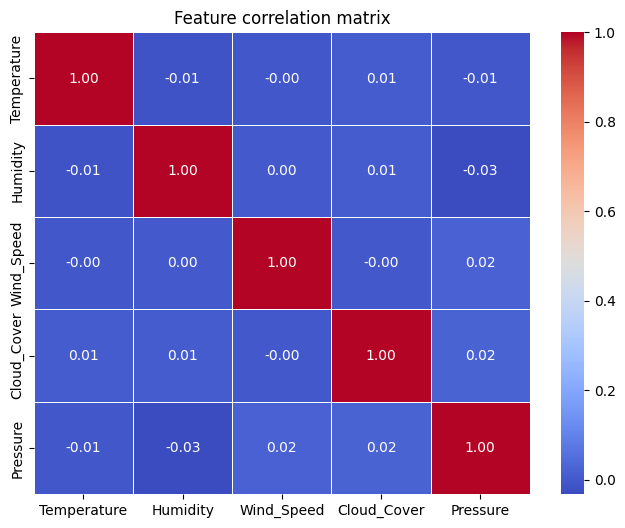

In [76]:
corr_matrix = X.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Feature correlation matrix")
plt.show()

The correlation matrix heatmap demonstrates that the features are completely independent.

In [77]:
scaler = StandardScaler()

In [78]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Random forest model implementation

In [79]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [80]:
rf_preds = rf_model.predict(X_test)
rf_acc = accuracy_score(y_test, rf_preds)

## Linear SVM model implementation

In [81]:
svm_linear = SVC(kernel='linear', random_state=42)
svm_linear.fit(X_train_scaled, y_train)

SVC(kernel='linear', random_state=42)

In [82]:
linear_preds = svm_linear.predict(X_test_scaled)
linear_acc = accuracy_score(y_test, linear_preds)

## RBF SVM model implementation

In [83]:
svm_rbf = SVC(kernel='rbf', random_state=42)
svm_rbf.fit(X_train_scaled, y_train)

SVC(random_state=42)

In [84]:
rbf_preds = svm_rbf.predict(X_test_scaled)
rbf_acc = accuracy_score(y_test, rbf_preds)


In [85]:
print("       EXPERIMENTAL RESULTS        ")
print(f"1. Random Forest Accuracy: {rf_acc:.4f}")
print(f"2. Linear SVM Accuracy:    {linear_acc:.4f}")
print(f"3. RBF SVM Accuracy:       {rbf_acc:.4f}")

       EXPERIMENTAL RESULTS        
1. Random Forest Accuracy: 1.0000
2. Linear SVM Accuracy:    0.9280
3. RBF SVM Accuracy:       0.9740


In [86]:
print("Random forest Classification Report:")
print(classification_report(y_test, rf_preds))

Random forest Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       437
           1       1.00      1.00      1.00        63

    accuracy                           1.00       500
   macro avg       1.00      1.00      1.00       500
weighted avg       1.00      1.00      1.00       500



In [87]:
print("Linear SVM Classification Report:")
print(classification_report(y_test, linear_preds))

Linear SVM Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.96      0.96       437
           1       0.73      0.68      0.70        63

    accuracy                           0.93       500
   macro avg       0.84      0.82      0.83       500
weighted avg       0.93      0.93      0.93       500



In [88]:
print("RBF SVM Classification Report:")
print(classification_report(y_test, rbf_preds))

RBF SVM Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99       437
           1       0.89      0.90      0.90        63

    accuracy                           0.97       500
   macro avg       0.94      0.94      0.94       500
weighted avg       0.97      0.97      0.97       500



In [89]:
cm_rf = confusion_matrix(y_test, rf_preds)
cm_linear = confusion_matrix(y_test, linear_preds)
cm_rbf = confusion_matrix(y_test, rbf_preds)

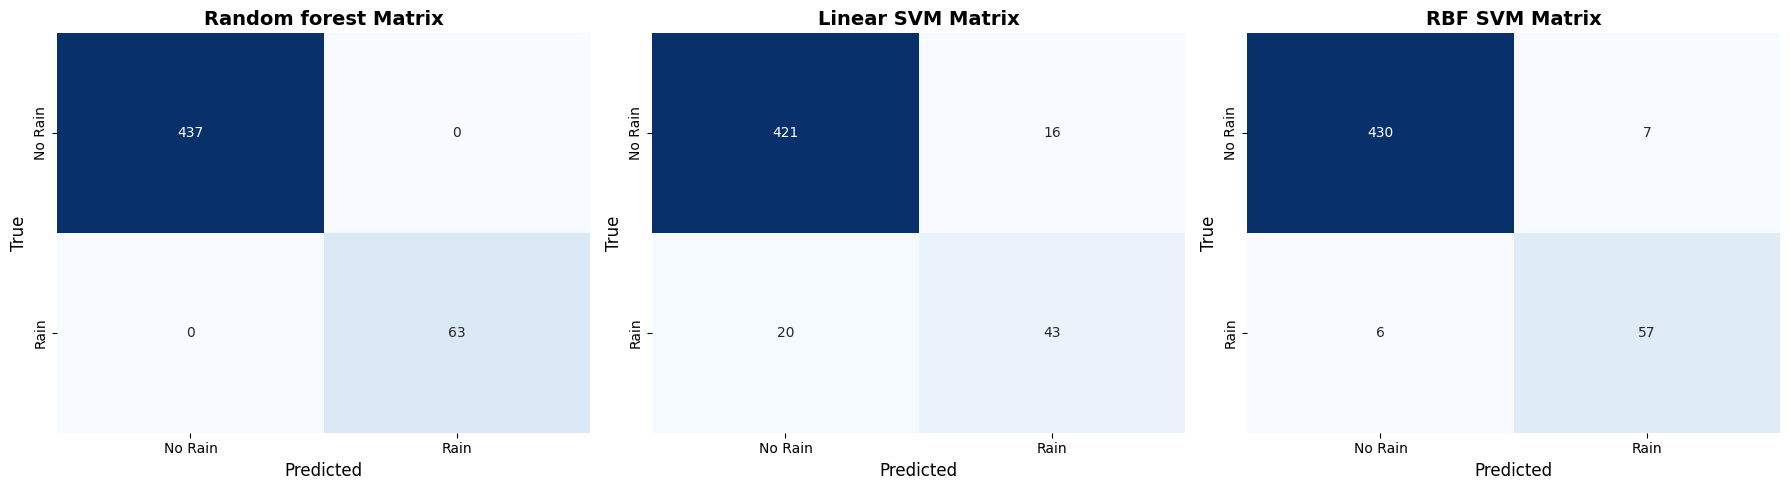

In [90]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
models = ['Random forest', 'Linear SVM', 'RBF SVM']
matrices = [cm_rf, cm_linear, cm_rbf]
for i, ax in enumerate(axes):
    sns.heatmap(matrices[i], annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['No Rain', 'Rain'], yticklabels=['No Rain', 'Rain'])
    ax.set_title(f'{models[i]} Matrix', fontsize=14, fontweight='bold')
    ax.set_xlabel('Predicted', fontsize=12)
    ax.set_ylabel('True', fontsize=12)

plt.tight_layout()
plt.show()

### Confusion matrix analysis

By plotting the exact error distributions from the testing set, we can extract the precise physical impact of our model selection:

* **Random Forest:** Confirms an absolute 0-error breakdown. 
* **Linear SVM:** It failed to predict rain on 20 critical days (False Negatives) and generated 16 false alarms (False Positives). 
* **RBF SVM:** By leveraging the Kernel Trick to project the data into a higher dimension, it dropped the missed-rain events from 20 down to just 6, while keeping false alarms to a minimum (7).

This visual experiment clearly demonstrates that when dealing with independent variables, non-linear transformation models are vital for capturing minority class patterns.
